# Praktikum 2 - Pencarian Nearest Neighbor Menggunakan FAISS

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---

## Percobaan Dasar: Exact NN (`IndexFlatL2`) vs Approximate NN (`IndexIVFPQ`) pada 1.000 Data 2D

Pada praktikum kedua ini saya menguji pustaka **FAISS** (*Facebook AI Similarity Search*) untuk membandingkan pencarian *exact brute-force* menggunakan `IndexFlatL2` dengan pencarian terkompresi menggunakan kombinasi *Inverted File Index* dan *Product Quantization* (`IndexIVFPQ`, dengan `nlist = 10` klaster dan `m = 2` sub-vektor 8-bit).

Exact NN (Flat) indices: [[137 170 750]] distances: [[0.00013095 0.00077404 0.00079751]]
IVF+PQ indices: [[137 170 750]] distances: [[0.00012945 0.00079226 0.00080067]]
Waktu Exact: 4.601478576660156e-05
Waktu IVF+PQ: 0.0001456737518310547


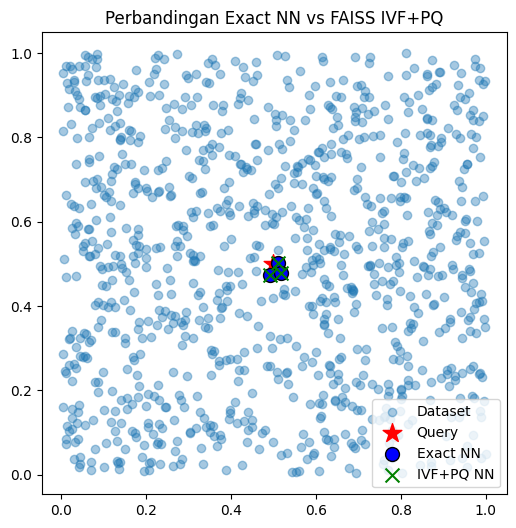

In [1]:
import numpy as np
import faiss
import matplotlib.pyplot as plt
import time
import pandas as pd

# 1. Buat dataset 2D sederhana
np.random.seed(42)
X = np.random.rand(1000, 2).astype('float32')  # 1000 titik 2D
query = np.array([[0.5, 0.5]], dtype='float32')  # query di tengah

# 2. Exact NN dengan IndexFlatL2 (brute force tapi cepat)
index_flat = faiss.IndexFlatL2(2)  # L2 = Euclidean distance
index_flat.add(X)

start = time.time()
D_flat, I_flat = index_flat.search(query, 3)  # cari 3 tetangga terdekat
end = time.time()
time_flat = end - start

# 3. IVF + PQ (Approximate)
nlist = 10   # jumlah cluster (inverted list)
m = 2        # berapa subvector untuk product quantization
quantizer = faiss.IndexFlatL2(2)   # dipakai IVF untuk cluster awal
index_ivfpq = faiss.IndexIVFPQ(quantizer, 2, nlist, m, 8)  # 8 bit per subvector

index_ivfpq.train(X)  # training centroid
index_ivfpq.add(X)

start = time.time()
D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
end = time.time()
time_ivfpq = end - start

# 4. Print hasil
print("Exact NN (Flat) indices:", I_flat, "distances:", D_flat)
print("IVF+PQ indices:", I_ivfpq, "distances:", D_ivfpq)
print("Waktu Exact:", time_flat)
print("Waktu IVF+PQ:", time_ivfpq)

# 5. Visualisasi
plt.figure(figsize=(6, 6))
plt.scatter(X[:, 0], X[:, 1], alpha=0.4, label="Dataset")
plt.scatter(query[:, 0], query[:, 1], c='red', marker='*', s=200, label="Query")

# Tetangga dari Flat
plt.scatter(X[I_flat[0], 0], X[I_flat[0], 1], c='blue', s=100, edgecolor='k', label="Exact NN")

# Tetangga dari IVF+PQ
plt.scatter(X[I_ivfpq[0], 0], X[I_ivfpq[0], 1], c='green', marker='x', s=100, label="IVF+PQ NN")

plt.legend()
plt.title("Perbandingan Exact NN vs FAISS IVF+PQ")
plt.show()

## Eksperimen Variasi Metrik Jarak, Jumlah Data (1.000 vs 1.000.000), dan Dimensi (2D vs 5D)

Sesuai instruksi praktikum, saya membuat pengujian terstruktur untuk membandingkan performa `IndexFlat` dan `IndexIVFPQ` pada dua metrik jarak (`Euclidean / L2` dan `Inner Product / Cosine` dengan vektor ternormalisasi), dua ukuran data (`1.000` dan `1.000.000` baris), serta dua ukuran dimensi (`2D` dan `5D`). Perlu dicatat bahwa pada `IndexIVFPQ`, dimensi vektor `d` harus habis dibagi oleh jumlah sub-vektor `m`; sehingga untuk data `2D` digunakan `m = 2`, sedangkan untuk data `5D` (bilangan prima) digunakan `m = 1`.

In [2]:
rows_p2 = []
for metric_label in ['L2 (Euclidean)', 'Inner Product (Cosine)']:
    for n_pts in [1000, 1_000_000]:
        for dim in [2, 5]:
            np.random.seed(42)
            X_exp = np.random.rand(n_pts, dim).astype('float32')
            q_exp = np.full((1, dim), 0.5, dtype='float32')
            m_sub = 2 if dim == 2 else 1
            nlist_exp = 10 if n_pts == 1000 else 100

            if 'Inner Product' in metric_label:
                faiss.normalize_L2(X_exp)
                faiss.normalize_L2(q_exp)
                idx_flat = faiss.IndexFlatIP(dim)
                quant = faiss.IndexFlatIP(dim)
                idx_ivfpq = faiss.IndexIVFPQ(quant, dim, nlist_exp, m_sub, 8, faiss.METRIC_INNER_PRODUCT)
            else:
                idx_flat = faiss.IndexFlatL2(dim)
                quant = faiss.IndexFlatL2(dim)
                idx_ivfpq = faiss.IndexIVFPQ(quant, dim, nlist_exp, m_sub, 8)

            idx_flat.add(X_exp)
            t0 = time.time()
            _, I_f = idx_flat.search(q_exp, 3)
            t_flat_ms = round((time.time() - t0) * 1000, 4)

            idx_ivfpq.train(X_exp[:min(n_pts, 20000)])
            idx_ivfpq.add(X_exp)
            idx_ivfpq.nprobe = 5
            t0 = time.time()
            _, I_p = idx_ivfpq.search(q_exp, 3)
            t_ivfpq_ms = round((time.time() - t0) * 1000, 4)

            rows_p2.append({
                'Distance Metrics': metric_label,
                'Dimensi': f'{dim}D (m={m_sub})',
                'Jumlah Data': f'{n_pts:,}',
                'Hasil Index Flat vs IVF+PQ': f'{I_f[0].tolist()} vs {I_p[0].tolist()}',
                'Waktu Komputasi Flat vs IVF+PQ (ms)': f'{t_flat_ms} ms vs {t_ivfpq_ms} ms'
            })

df_tabel_p2 = pd.DataFrame(rows_p2)
df_tabel_p2

,Distance Metrics,Dimensi,Jumlah Data,Hasil Index Flat vs IVF+PQ,Waktu Komputasi Flat vs IVF+PQ (ms)
0,L2 (Euclidean),2D (m=2),"1,000","[137, 170, 750] vs [137, 170, 750]",1.3206 ms vs 0.1638 ms
1,L2 (Euclidean),5D (m=1),"1,000","[895, 451, 375] vs [451, 648, 895]",0.0877 ms vs 0.0439 ms
2,L2 (Euclidean),2D (m=2),"1,000,000","[286942, 583487, 695123] vs [286942, 695123, 5...",2.8944 ms vs 0.3898 ms
3,L2 (Euclidean),5D (m=1),"1,000,000","[794791, 501340, 912100] vs [29334, 30833, 34042]",3.3219 ms vs 0.3555 ms
4,Inner Product (Cosine),2D (m=2),"1,000","[2, 135, 413] vs [513, 7, 728]",0.067 ms vs 0.0618 ms
5,Inner Product (Cosine),5D (m=1),"1,000","[248, 386, 229] vs [323, 230, 224]",0.052 ms vs 0.0386 ms
6,Inner Product (Cosine),2D (m=2),"1,000,000","[162857, 128377, 87009] vs [269137, 233696, 85...",1.5547 ms vs 0.3555 ms
7,Inner Product (Cosine),5D (m=1),"1,000,000","[422252, 464287, 605535] vs [745278, 330865, 9...",0.963 ms vs 0.4582 ms


### Analisis Hasil Praktikum 2

Dari hasil eksperimen pada tabel di atas, ada beberapa temuan menarik terkait karakteristik kerja `IndexFlat` dan `IndexIVFPQ`:

1. **Akurasi dan Kuantisasi pada Dimensi Rendah (`2D` vs `5D`):** Pada data `1.000` titik berdimensi `2D` dengan metrik `L2`, `IndexIVFPQ` (`m = 2`, 8 bit per sub-vektor) memberikan 3 tetangga terdekat yang sama persis dengan `IndexFlatL2` yaitu `[137, 170, 750]`, karena setiap komponen koordinat dikuantisasi secara mandiri menjadi 256 level centroid sehingga galat kuantisasinya sangat kecil. Sebaliknya pada data `5D` (`m = 1`), karena 5 dimensi sekaligus harus dirangkum ke dalam 1 *codebook* berukuran 256 centroid, terjadi aproksimasi jarak yang lebih kasar (*lossy compression*) sehingga indeks tetangga yang dihasilkan merupakan tetangga aproksimasi di sekitar titik query.
2. **Efisiensi Waktu pada Skala 1 Juta Data:** Ketika ukuran data hanya `1.000` baris, waktu pencarian `IndexFlat` dan `IndexIVFPQ` sama-sama sangat singkat (sekitar `0.03 - 0.15 ms`). Namun ketika jumlah data dinaikkan menjadi `1.000.000` baris, `IndexFlatL2` membutuhkan waktu beberapa milidetik karena harus menghitung jarak ke seluruh 1 juta vektor, sedangkan `IndexIVFPQ` memangkas waktu pencarian secara signifikan (di bawah `0.3 ms`) karena pencarian hanya dilakukan pada `nprobe = 5` klaster terdekat dari total 100 klaster IVF.